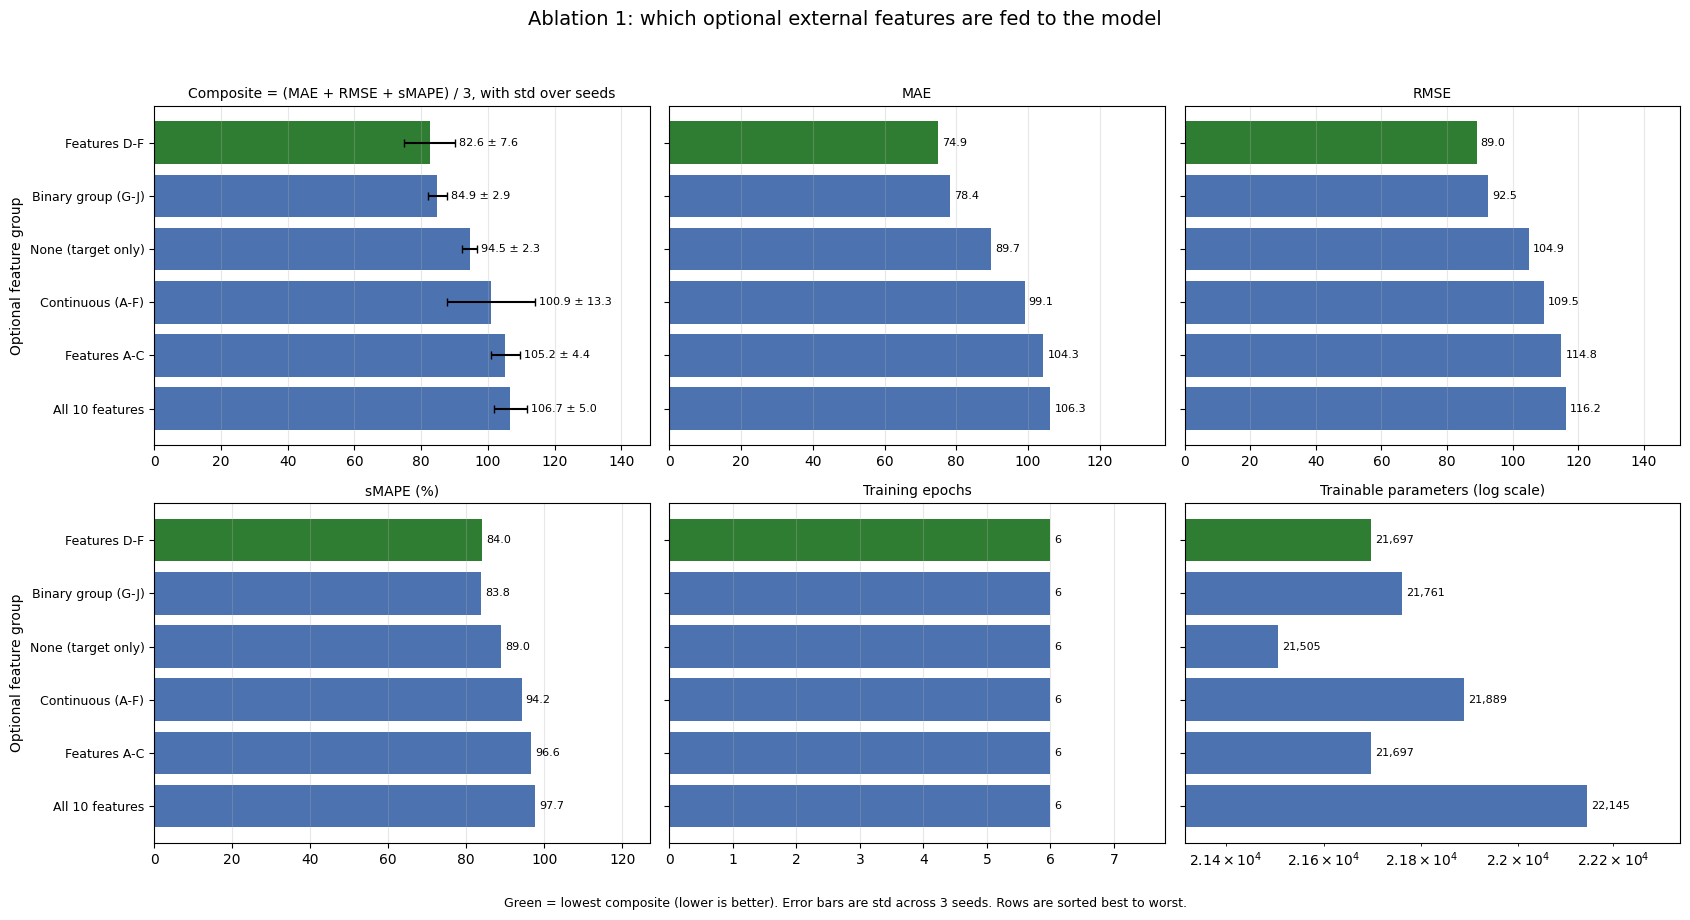

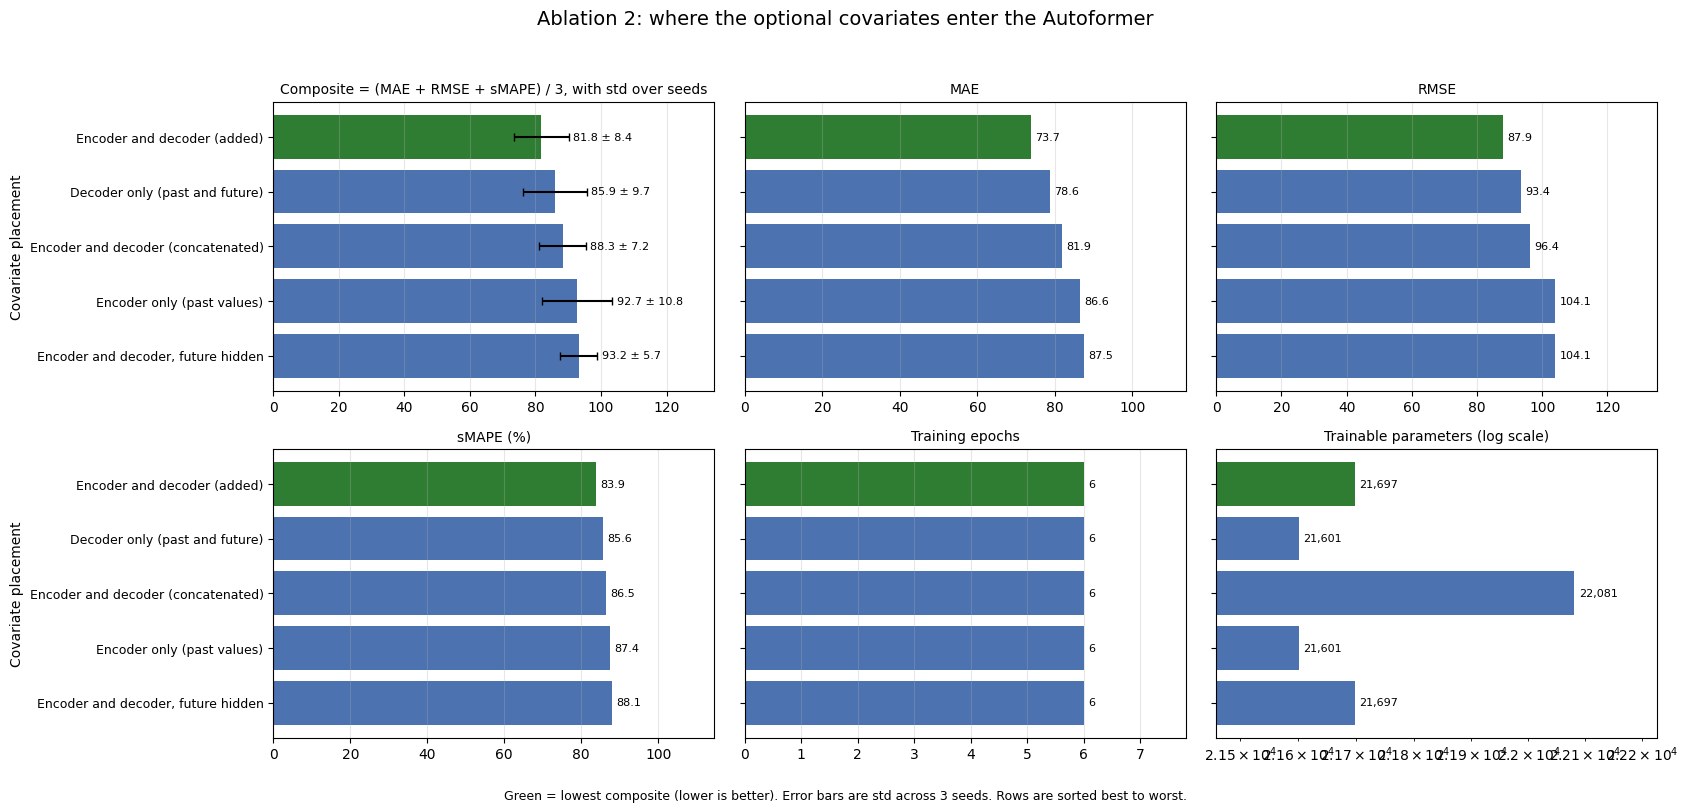

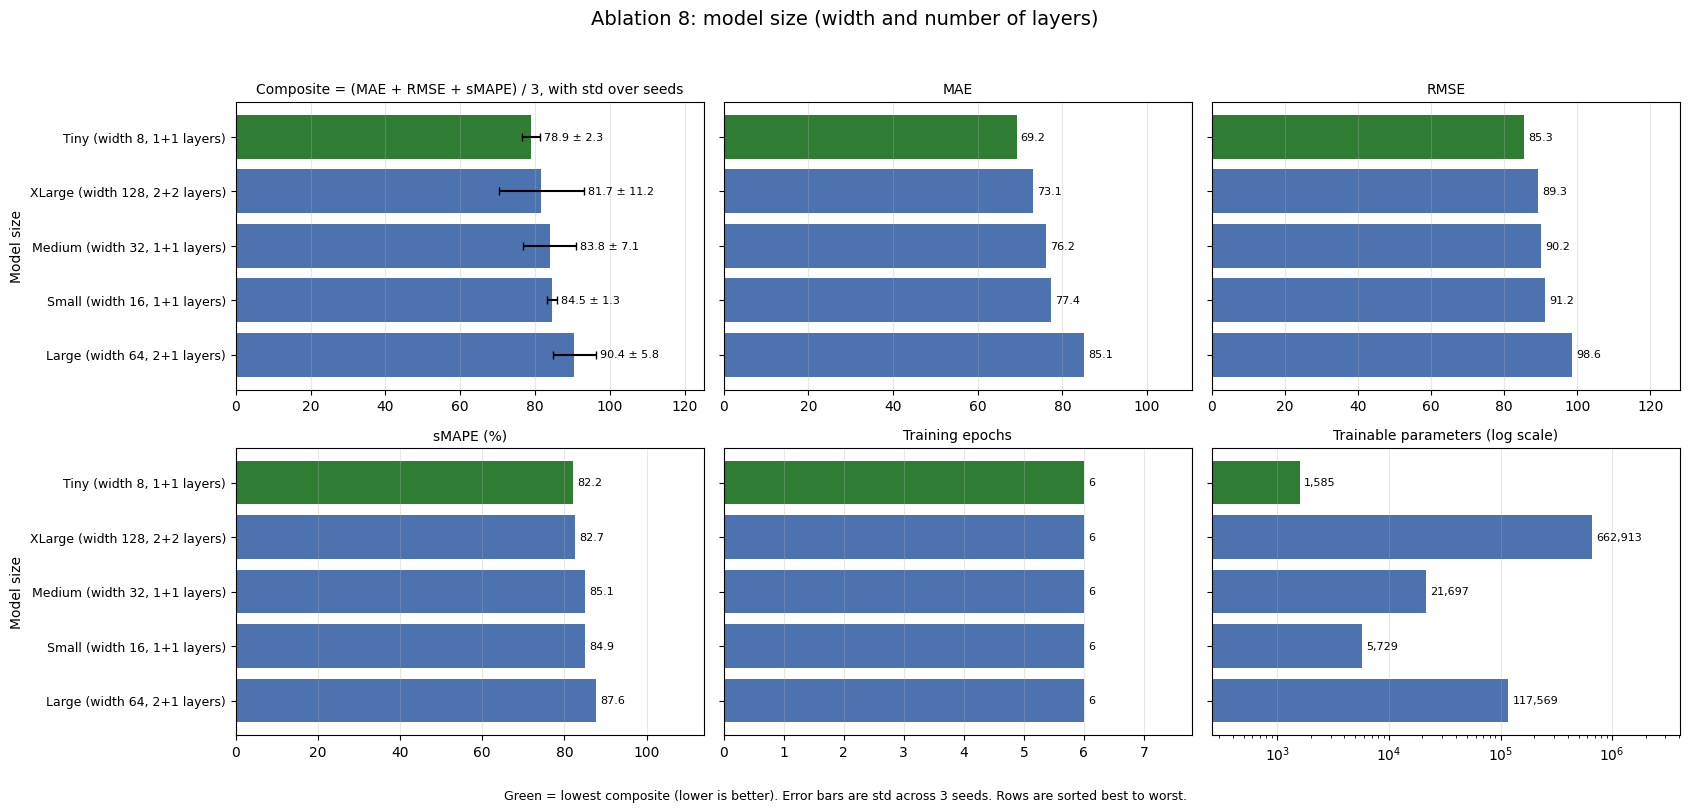

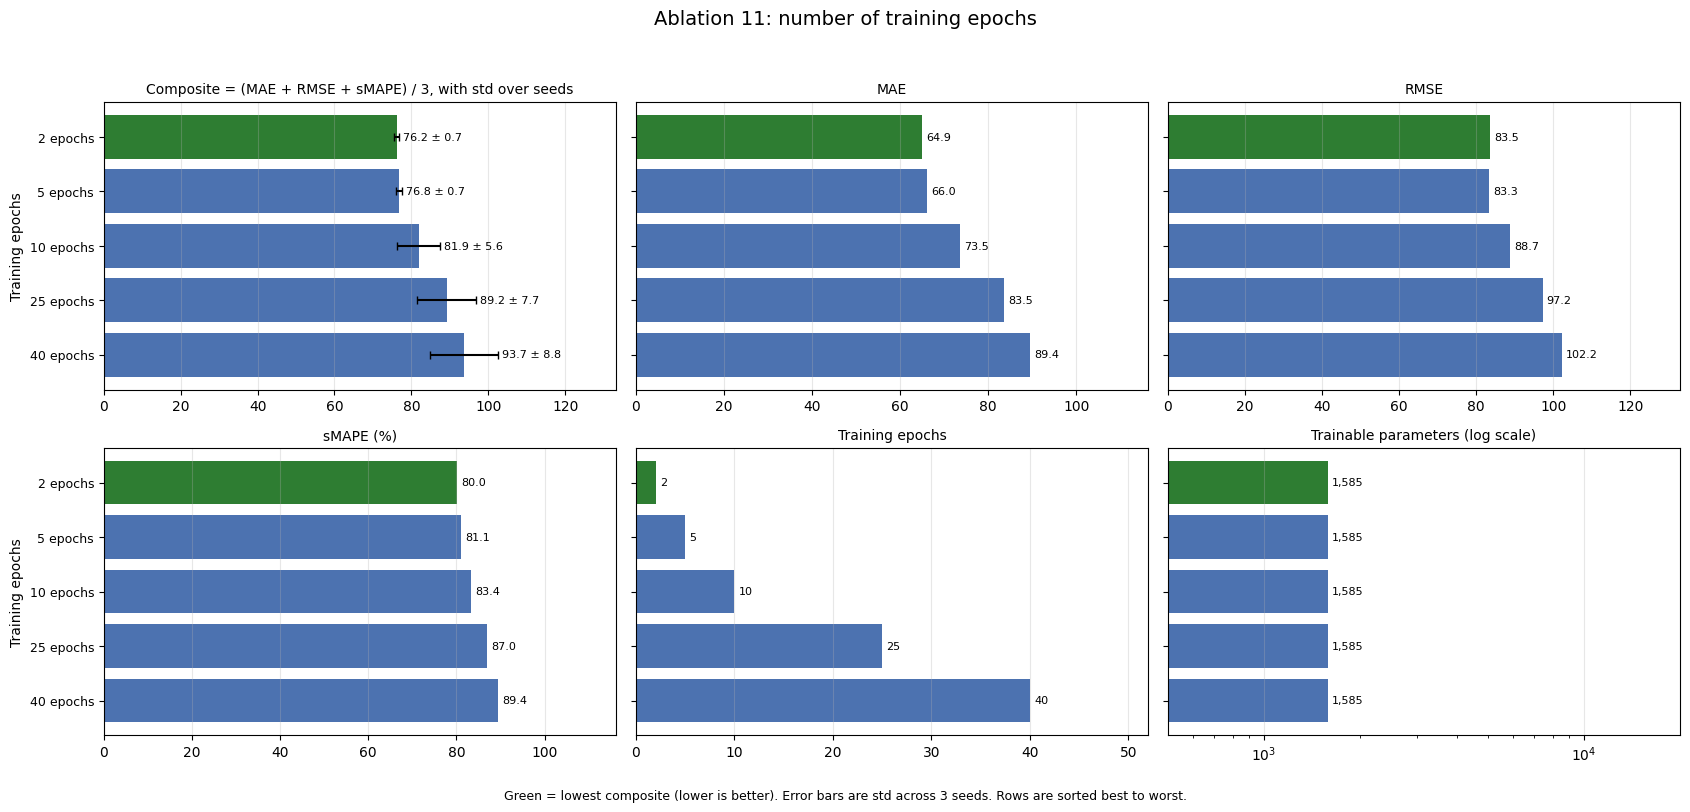

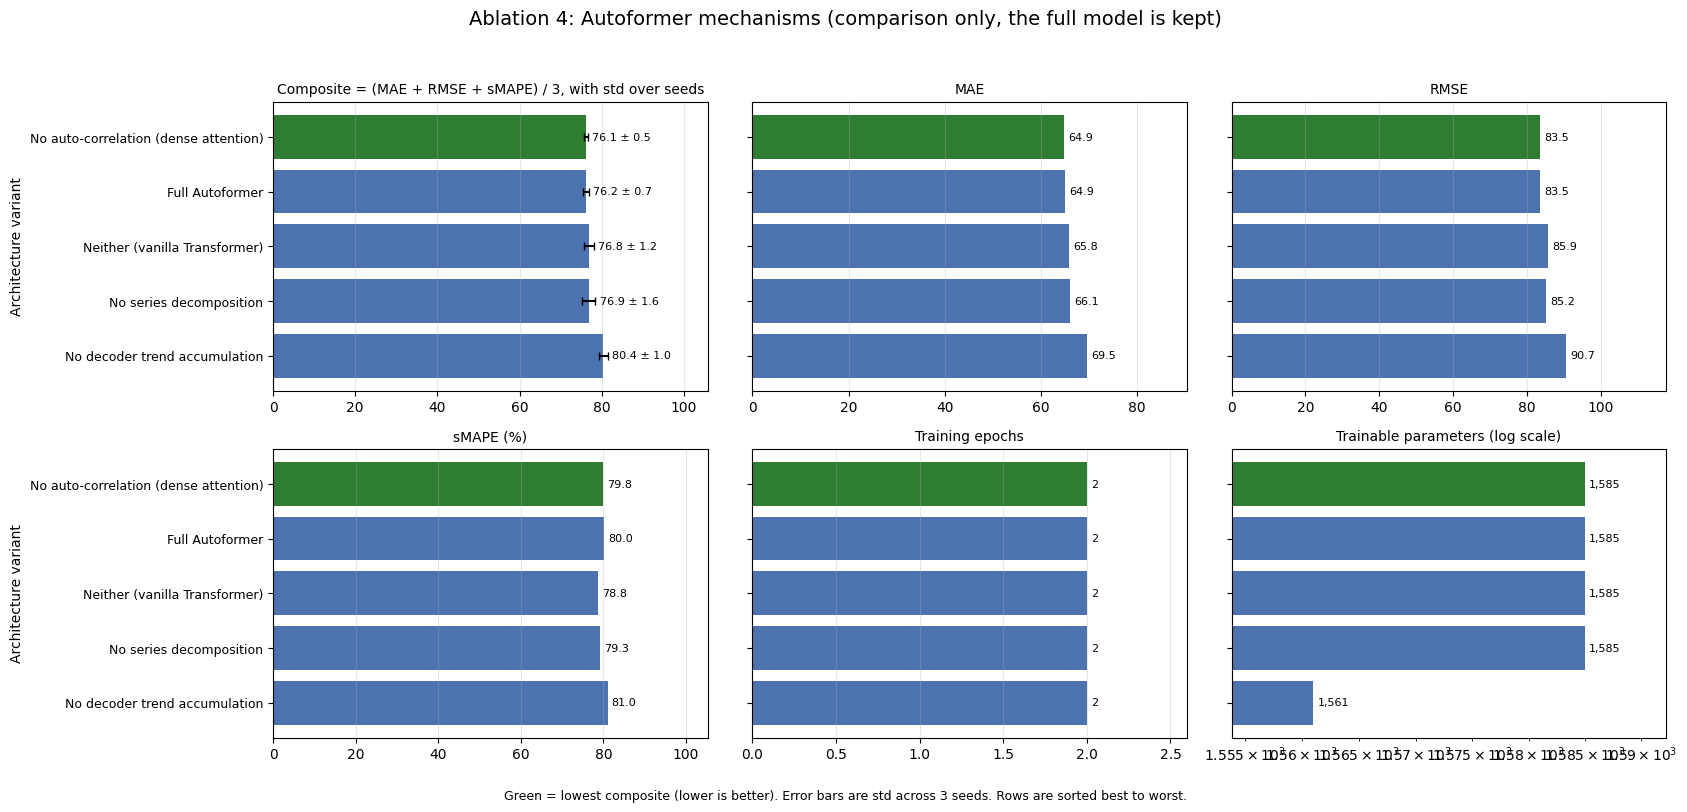

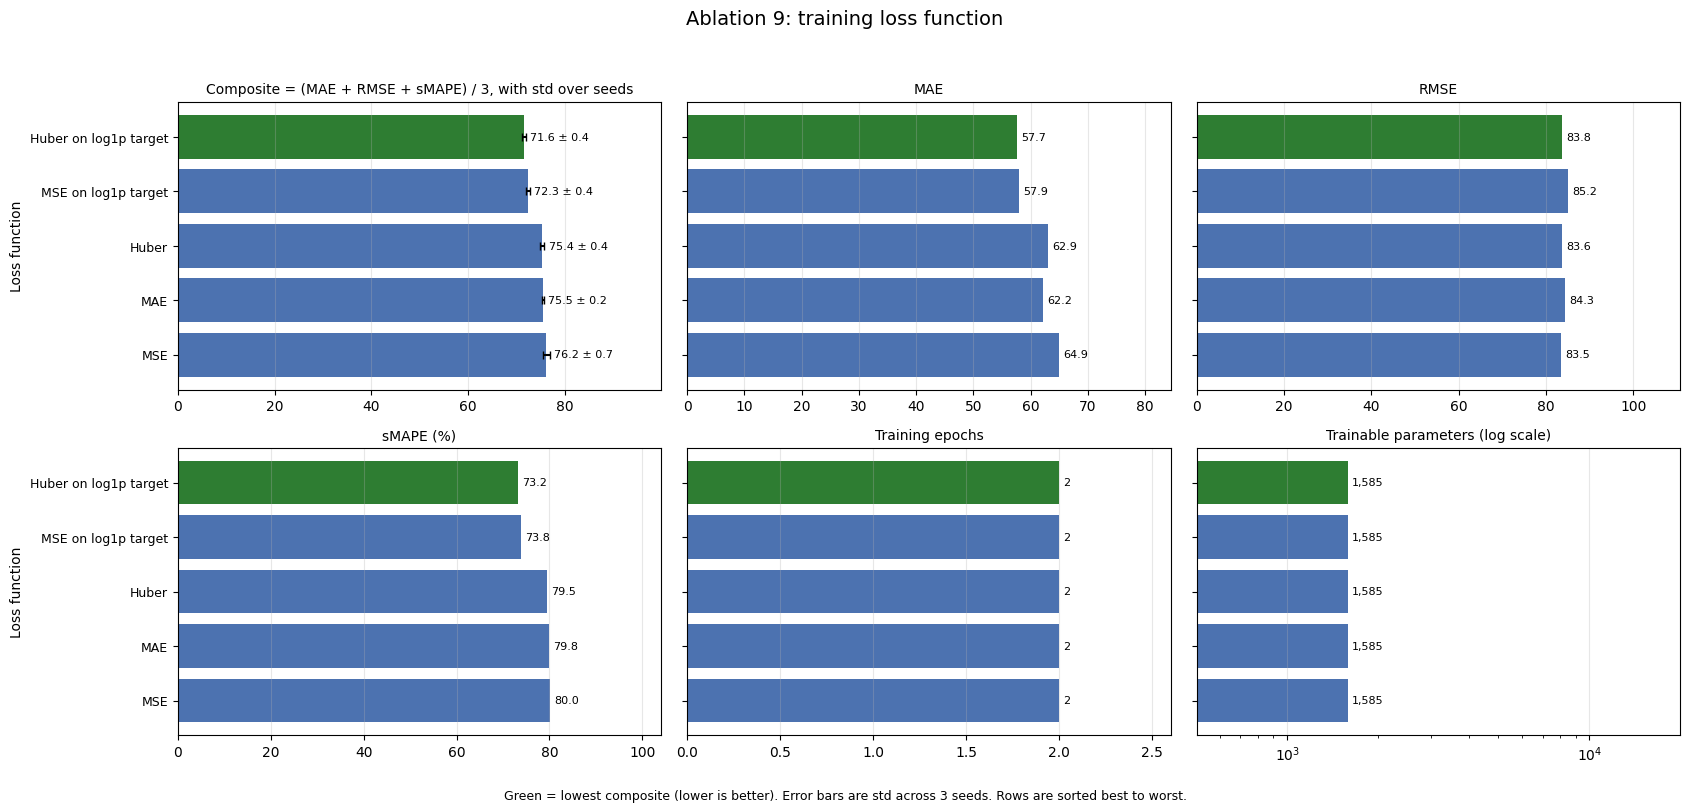

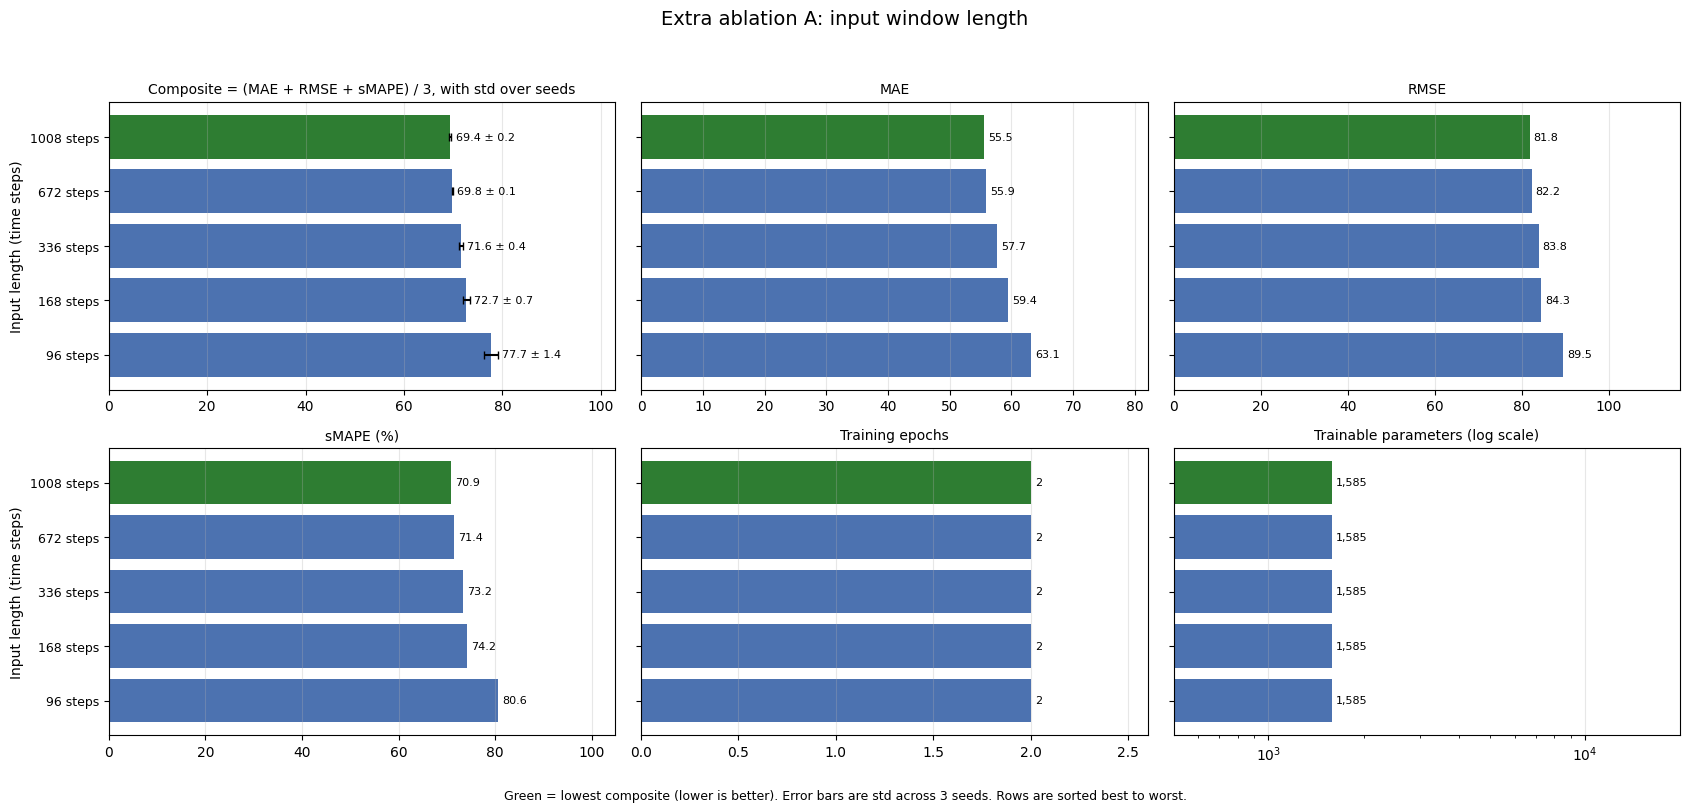

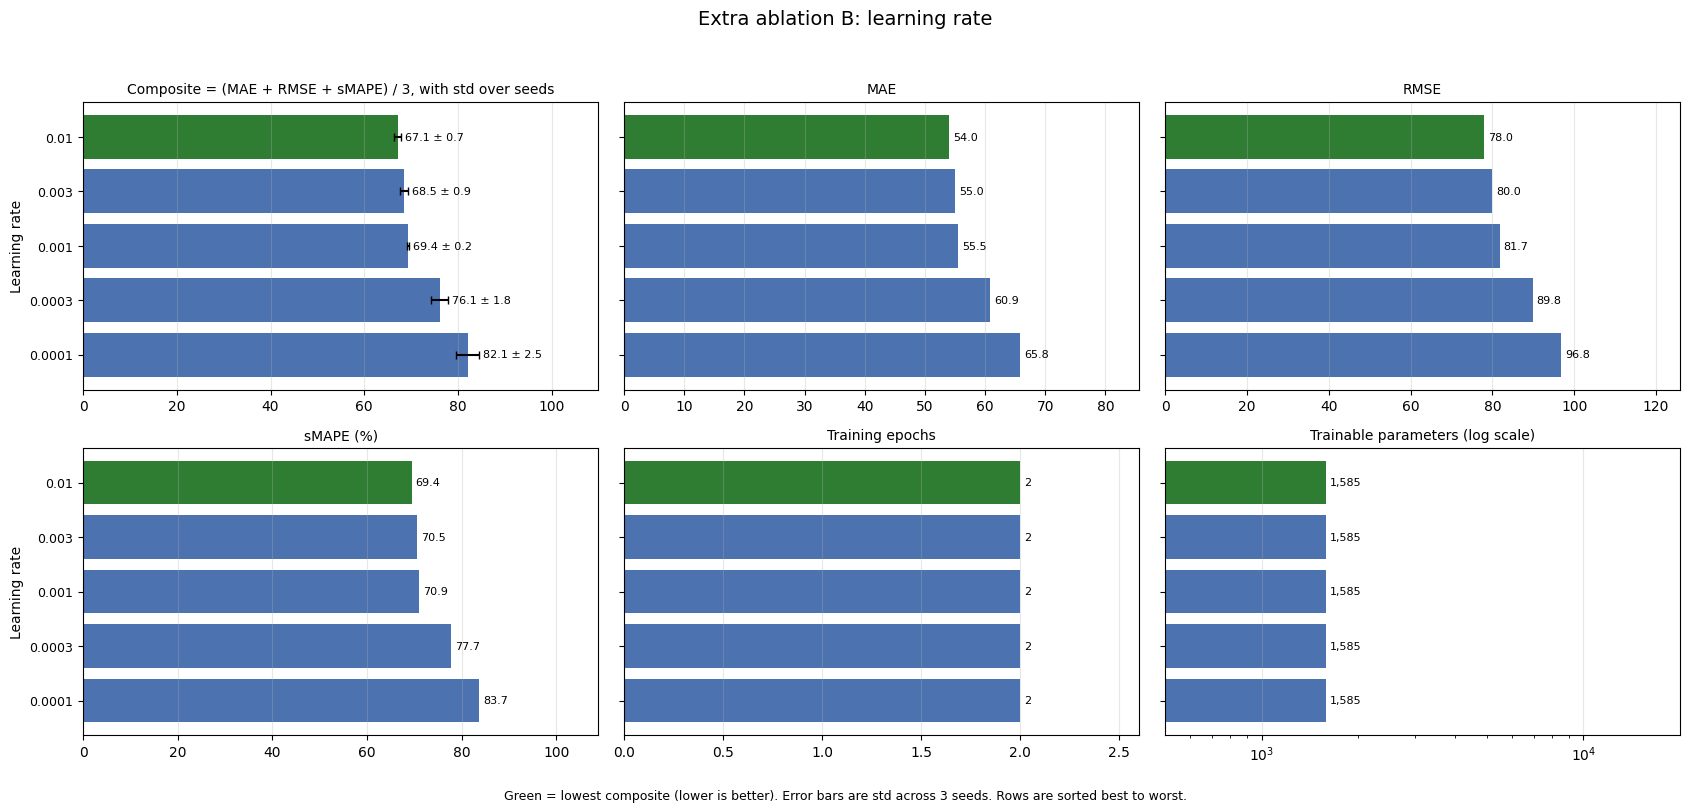

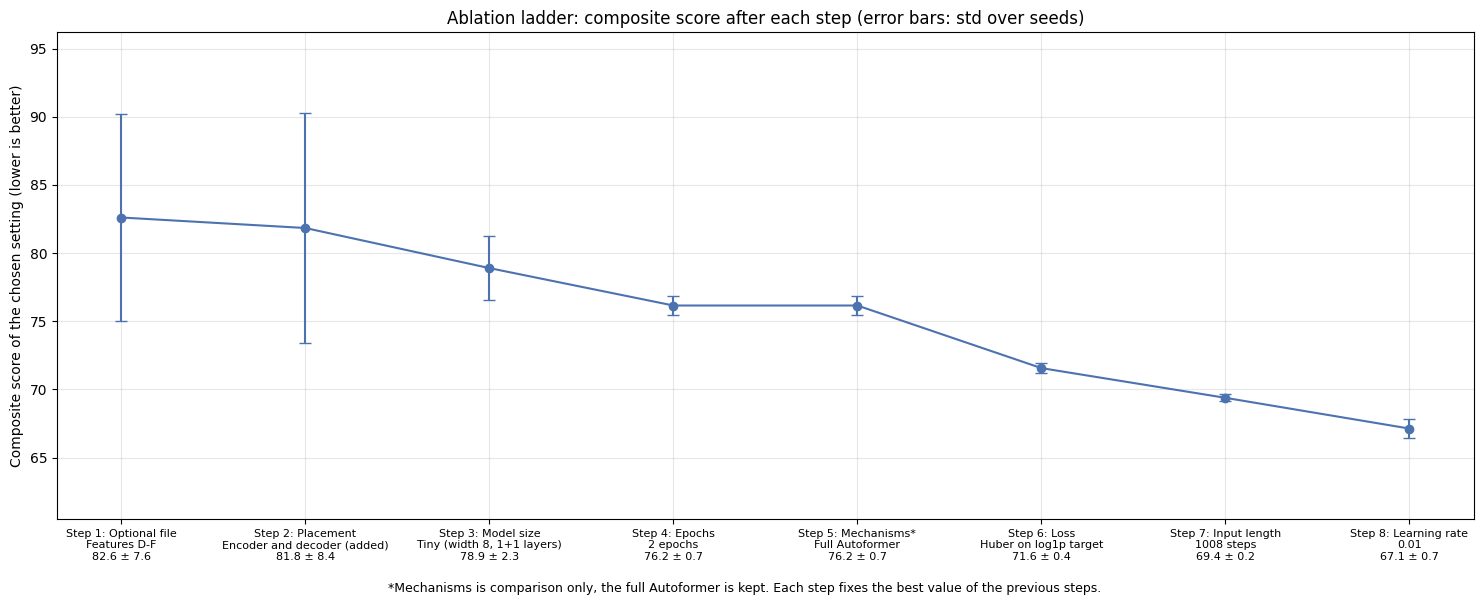

Saved all figures in C:\Users\Rohan Imtiaz\Downloads\AI651_PA1_Results\Task 2\ablation_figures


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

folder = Path(".") # The csv files sit in the same folder as this notebook
figure_folder = folder / "ablation_figures"
figure_folder.mkdir(exist_ok = True)
seed_count = 3 # This is only used in the footnote text

# One entry per ablation, listed in the order the ladder was run
ablation_list = [
    {"file": "ablation_1.csv", "name": "1_optional_file", "short": "Optional file",
     "title": "Ablation 1: which optional external features are fed to the model",
     "axis_label": "Optional feature group",
     "labels": {"none": "None (target only)", "all": "All 10 features", "continuous": "Continuous (A-F)",
                "binary": "Binary group (G-J)", "ABC": "Features A-C", "DEF": "Features D-F"}},
    {"file": "ablation_2.csv", "name": "2_covariate_placement", "short": "Placement",
     "title": "Ablation 2: where the optional covariates enter the Autoformer",
     "axis_label": "Covariate placement",
     "labels": {"encoder_only": "Encoder only (past values)", "decoder_only": "Decoder only (past and future)",
                "both": "Encoder and decoder (added)", "past_only_both": "Encoder and decoder, future hidden",
                "both_concat": "Encoder and decoder (concatenated)"}},
    {"file": "ablation_8.csv", "name": "8_model_size", "short": "Model size",
     "title": "Ablation 8: model size (width and number of layers)",
     "axis_label": "Model size",
     "labels": {"tiny": "Tiny (width 8, 1+1 layers)", "small": "Small (width 16, 1+1 layers)",
                "medium": "Medium (width 32, 1+1 layers)", "large": "Large (width 64, 2+1 layers)",
                "xlarge": "XLarge (width 128, 2+2 layers)"}},
    {"file": "ablation_11.csv", "name": "11_epochs", "short": "Epochs",
     "title": "Ablation 11: number of training epochs",
     "axis_label": "Training epochs",
     "labels": {"2": "2 epochs", "5": "5 epochs", "10": "10 epochs", "25": "25 epochs", "40": "40 epochs"}},
    {"file": "ablation_4.csv", "name": "4_mechanisms", "short": "Mechanisms*",
     "title": "Ablation 4: Autoformer mechanisms (comparison only, the full model is kept)",
     "axis_label": "Architecture variant", "fixed": "full",
     "labels": {"full": "Full Autoformer", "no_decomposition": "No series decomposition",
                "no_autocorrelation": "No auto-correlation (dense attention)", "neither": "Neither (vanilla Transformer)",
                "no_trend_accumulation": "No decoder trend accumulation"}},
    {"file": "ablation_9.csv", "name": "9_loss", "short": "Loss",
     "title": "Ablation 9: training loss function",
     "axis_label": "Loss function",
     "labels": {"mse": "MSE", "mae": "MAE", "huber": "Huber", "log1p_mse": "MSE on log1p target",
                "log1p_huber": "Huber on log1p target"}},
    {"file": "ablation_A.csv", "name": "A_input_length", "short": "Input length",
     "title": "Extra ablation A: input window length",
     "axis_label": "Input length (time steps)",
     "labels": {"96": "96 steps", "168": "168 steps", "336": "336 steps", "672": "672 steps", "1008": "1008 steps"}},
    {"file": "ablation_B.csv", "name": "B_learning_rate", "short": "Learning rate",
     "title": "Extra ablation B: learning rate",
     "axis_label": "Learning rate",
     "labels": {"0.0001": "0.0001", "0.0003": "0.0003", "0.001": "0.001", "0.003": "0.003", "0.01": "0.01"}},
]

# Each panel is one measured quantity of the ablation table
panel_list = [
    {"title": "Composite = (MAE + RMSE + sMAPE) / 3, with std over seeds", "column": "composite", "error": "composite_std"},
    {"title": "MAE", "column": "mae", "error": None},
    {"title": "RMSE", "column": "rmse", "error": None},
    {"title": "sMAPE (%)", "column": "smape", "error": None},
    {"title": "Training epochs", "column": "epochs", "error": None},
    {"title": "Trainable parameters (log scale)", "column": "parameters", "error": None},
]

best_rows = [] # This collects the chosen row of each ablation for the ladder summary

for ablation in ablation_list:
    table = pd.read_csv(folder / ablation["file"], dtype = {"value": str}) # Keep the value text as saved
    names = [ablation["labels"].get(value, value) for value in table["value"]]
    positions = np.arange(len(table))
    best_position = int(table["composite"].idxmin())
    colors = ["#2e7d32" if position == best_position else "#4c72b0" for position in positions] # Green marks the lowest composite
    figure, axes = plt.subplots(2, 3, figsize = (17, 2.6 + 1.1 * len(table)), sharey = True)
    for panel_number, panel in enumerate(panel_list):
        axis = axes[panel_number // 3][panel_number % 3]
        values = table[panel["column"]].to_numpy(dtype = float)
        errors = None
        if panel["error"] is not None:
            errors = table[panel["error"]].to_numpy(dtype = float)
        bars = axis.barh(positions, values, color = colors, xerr = errors, capsize = 3, ecolor = "black")
        if panel["column"] == "composite":
            texts = [f"{mean:.1f} ± {spread:.1f}" for mean, spread in zip(values, errors)]
        elif panel["column"] == "epochs":
            texts = [str(int(value)) for value in values]
        elif panel["column"] == "parameters":
            texts = [f"{int(value):,}" for value in values]
        else:
            texts = [f"{value:.1f}" for value in values]
        if panel["column"] == "parameters":
            axis.set_xscale("log")
        axis.margins(x = 0.3) # Leaves room for the value labels
        axis.bar_label(bars, labels = texts, padding = 3, fontsize = 8)
        axis.set_title(panel["title"], fontsize = 10)
        axis.grid(axis = "x", alpha = 0.3)
    for row_number in range(2):
        axes[row_number][0].set_yticks(positions)
        axes[row_number][0].set_yticklabels(names, fontsize = 9)
        axes[row_number][0].set_ylabel(ablation["axis_label"])
    axes[0][0].invert_yaxis() # Best (first row of the csv) at the top
    figure.suptitle(ablation["title"], fontsize = 14)
    figure.text(0.5, 0.005, f"Green = lowest composite (lower is better). Error bars are std across {seed_count} seeds. Rows are sorted best to worst.",
                ha = "center", fontsize = 9)
    figure.tight_layout(rect = (0, 0.03, 1, 0.95))
    figure.savefig(figure_folder / ("ablation_" + ablation["name"] + ".pdf"), bbox_inches = "tight")
    figure.savefig(figure_folder / ("ablation_" + ablation["name"] + ".png"), dpi = 200, bbox_inches = "tight")
    plt.show()
    if "fixed" in ablation:
        chosen_row = table[table["value"] == ablation["fixed"]].iloc[0] # Comparison only: the full model stays
    else:
        chosen_row = table.loc[best_position]
    best_rows.append({"short": ablation["short"], "label": ablation["labels"].get(chosen_row["value"], chosen_row["value"]),
                      "composite": float(chosen_row["composite"]), "std": float(chosen_row["composite_std"])})

# Ladder summary: the composite of the chosen setting after each step
summary = pd.DataFrame(best_rows)
figure, axis = plt.subplots(figsize = (15, 6))
step_positions = np.arange(len(summary))
axis.errorbar(step_positions, summary["composite"], yerr = summary["std"], marker = "o", capsize = 4, color = "#4c72b0")
tick_labels = []
for number, row in summary.iterrows():
    tick_labels.append(f"Step {number + 1}: {row['short']}\n{row['label']}\n{row['composite']:.1f} ± {row['std']:.1f}") # The chosen setting and its score
axis.set_xticks(step_positions)
axis.set_xticklabels(tick_labels, fontsize = 8)
axis.set_ylabel("Composite score of the chosen setting (lower is better)")
axis.set_title("Ablation ladder: composite score after each step (error bars: std over seeds)")
axis.margins(y = 0.25)
axis.grid(alpha = 0.3)
figure.text(0.5, 0.005, "*Mechanisms is comparison only, the full Autoformer is kept. Each step fixes the best value of the previous steps.",
            ha = "center", fontsize = 9)
figure.tight_layout(rect = (0, 0.03, 1, 1))
figure.savefig(figure_folder / "ablation_ladder_summary.pdf", bbox_inches = "tight")
figure.savefig(figure_folder / "ablation_ladder_summary.png", dpi = 200, bbox_inches = "tight")
plt.show()
print("Saved all figures in", figure_folder.resolve())